# Beyond Chunk Size: Chunking × Embedding × Retrieval Study for RAG
**Course:** Prompt Engineering and Optimization for Generative AI (UE24AM343AB5) — Mini Project, Problem Statement 6

A multi-domain empirical study of **chunking strategies**, **embedding models** and **retrieval pipelines** (dense → hybrid → hybrid + reranker), ending in a **decision matrix** and a small **Config Advisor** app.

### Hypotheses
1. **H1:** Structure-aware chunking beats fixed-size / semantic chunking on structured documents (API docs, legal text).
2. **H2:** A reranker narrows the performance gap between chunking strategies.
3. **H3:** Compressed embeddings (truncated / binary) lose little accuracy but save a lot of storage and latency.

### Pipeline (staged, so the grid stays small)
| Stage | What runs | LLM needed? |
|---|---|---|
| Gold set | LLM drafts questions with verbatim evidence → **you verify by hand** | Yes (one-off) |
| 1 | All chunkers × 1 fixed embedder (dense) | No |
| 2 | Top chunkers × all embedders (dense) | No |
| 3a | All chunkers × best embedder × {dense, hybrid, hybrid+rerank} → tests **H2** | No |
| 3b | Top (chunker, embedder) pairs × modes, with answer generation + groundedness | Yes |
| 4 | Efficiency: truncated dims, binary quantization, latency, index size → tests **H3** | No |
| Analysis | CIs, heatmaps, Pareto plot, decision matrix, provider cross-check, advisor app | – |

**Key design choice:** all retrieval metrics are computed from **character offsets**, so they are comparable across chunkers of any size (no LLM needed for retrieval metrics).

**LLM provider is a switchable option** (`PROVIDER = "gemini"`, `"openai"`, `"openrouter"` or `"ollama"` for local models). Embeddings stay local (Hugging Face) by default.

## 0. Install
Run once. (On Colab/Kaggle this works as-is; restart the kernel if pip asks you to.)

In [1]:
%pip install -q ipywidgets sentence-transformers faiss-cpu rank_bm25 python-dotenv google-genai openai pypdf beautifulsoup4 lxml requests pandas numpy matplotlib scipy tqdm streamlit

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration
Create a `.env` file next to this notebook (add it to `.gitignore`). **Only the API key is needed** - the notebook uses it to list the models your key can access and lets you pick one (section 2b):
```
LLM_PROVIDER=gemini                 # gemini | openai | openrouter | ollama
GEMINI_API_KEY=...
OPENAI_API_KEY=...
OPENROUTER_API_KEY=...
# optional: skip the picker by pinning a model
# GEMINI_MODEL=...
# OPENAI_MODEL=...
# OPENROUTER_MODEL=...
# OPENROUTER_FALLBACKS=             # optional, comma-separated backup model ids
# --- local models via Ollama (no key needed) ---
# OLLAMA_HOST=http://localhost:11434   # default
# OLLAMA_MODEL=llama3.1:8b
# OLLAMA_NUM_CTX=8192
```
No key in `.env`? The picker will ask for it (hidden input). Model ids change often and free-tier models rotate, so none are hard-coded.

In [2]:
import os, re, json, time, math, hashlib, random, sqlite3, warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np, pandas as pd
from tqdm.auto import tqdm
from dotenv import load_dotenv
warnings.filterwarnings("ignore")
load_dotenv()

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ============================ USER OPTIONS ============================
PROVIDER       = os.getenv("LLM_PROVIDER", "gemini")  # "gemini" | "openai" | "openrouter" | "ollama" (local)   <-- switchable option
AUTO_DETECT_OLLAMA = True  # choose_model() checks for a local Ollama server and offers its models
AUTO_FALLBACK  = False     # if the chosen provider keeps failing, try the other one (if its key is set)
FAST_MODE      = False     # True = tiny run to test the notebook end-to-end (few chunkers/embedders/questions)
USE_API_EMBEDDERS = False  # True = also compare Gemini / OpenAI embeddings (needs keys; rate-limited on free tiers)

TOPK           = 5         # chunks/units passed to the generator
CAND           = 30        # candidates fetched before fusion / reranking
RERANK_TOPN    = 20        # candidates the cross-encoder re-scores
RERANK_MODEL   = "cross-encoder/ms-marco-MiniLM-L-6-v2"   # or "BAAI/bge-reranker-base" (bigger, better)
REL_THRESH     = 0.3       # a retrieved unit is "relevant" if it covers >=30% of an evidence span
LAT_N          = 15        # queries used to measure latency
RRF_K          = 60        # reciprocal-rank-fusion constant

N_SINGLE, N_MULTI, N_UNANS = (15, 4, 3) if FAST_MODE else (60, 15, 10)   # gold questions per corpus
LLM_EVAL_N     = 10 if FAST_MODE else 30   # questions per config sent to the LLM (generation + judge)
TOP_CHUNKERS   = 2 if FAST_MODE else 3     # Stage 1 -> Stage 2
TOP_PAIRS      = 1 if FAST_MODE else 2     # Stage 2 -> Stage 3b
REQUIRE_VERIFIED = True    # if any gold row is marked verified=True, only verified rows are used

STAGE1_EMBEDDER = "bge-small"   # fixed embedder used while comparing chunkers
SEM_EMBED_NAME  = "minilm"      # embedder used only to *split* text in semantic chunking
MODES = ["dense", "hybrid", "hybrid+rerank"]
# ======================================================================

DATA_DIR  = Path("data");   DATA_DIR.mkdir(exist_ok=True)
EVAL_DIR  = Path("eval");   EVAL_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path("cache");  (CACHE_DIR/"emb").mkdir(parents=True, exist_ok=True)
OUT_DIR   = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
except Exception:
    DEVICE = "cpu"
print("device:", DEVICE, "| provider:", PROVIDER)

device: cpu | provider: gemini


## 2. LLM layer
One function `ask()` for everything. The cache key includes provider + model + prompt, so switching provider never mixes results and re-runs cost nothing.

In [3]:
_db = sqlite3.connect(str(CACHE_DIR/"llm_cache.db"), check_same_thread=False)
_db.execute("CREATE TABLE IF NOT EXISTS c (k TEXT PRIMARY KEY, v TEXT)")

_gem_client = None
def _gemini_client():
    global _gem_client
    if _gem_client is None:
        from google import genai
        _gem_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    return _gem_client

_or_client = None
def _openrouter_client():
    global _or_client
    if _or_client is None:
        from openai import OpenAI
        _or_client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.environ["OPENROUTER_API_KEY"])
    return _or_client

# ---------------- OpenAI ----------------
_oa_client = None
def _openai_client():
    global _oa_client
    if _oa_client is None:
        from openai import OpenAI
        _oa_client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])   # same key also powers the optional openai-small embedder
    return _oa_client

def _reset_clients():
    global _gem_client, _or_client, _oa_client
    _gem_client = None; _or_client = None; _oa_client = None       # rebuild clients with a new key

def _openai_chat(model, prompt, temperature):
    msgs = [{"role": "user", "content": prompt}]
    try:
        r = _openai_client().chat.completions.create(model=model, messages=msgs, temperature=temperature)
    except Exception as e:
        if "temperature" in str(e).lower():          # reasoning models (o-series / gpt-5) only accept the default temperature
            r = _openai_client().chat.completions.create(model=model, messages=msgs)
        else:
            raise
    return r.choices[0].message.content or ""

# ---------------- Ollama (local models) ----------------
def _norm_host(h):
    h = (h or "http://localhost:11434").strip().rstrip("/")
    if not h.startswith("http"):
        h = "http://" + h
    return h.replace("//0.0.0.0", "//localhost")
OLLAMA_HOST    = _norm_host(os.getenv("OLLAMA_HOST"))
OLLAMA_NUM_CTX = int(os.getenv("OLLAMA_NUM_CTX", "8192"))   # Ollama's default context is small; 5 chunks + prompt need more
OLLAMA_TIMEOUT = int(os.getenv("OLLAMA_TIMEOUT", "300"))
_OLLAMA_SKIP   = ("embed", "bge-", "minilm", "nomic", "mxbai", "snowflake-arctic")   # embedding-only models can't chat

def detect_ollama(timeout=1.5, quiet=True):
    """Return the list of local chat models if an Ollama server is reachable, else None."""
    import requests
    try:
        r = requests.get(f"{OLLAMA_HOST}/api/tags", timeout=timeout); r.raise_for_status()
    except Exception as e:
        if not quiet:
            print(f"No Ollama server at {OLLAMA_HOST} ({type(e).__name__}). Start it with `ollama serve`.")
        return None
    out = []
    for m in r.json().get("models", []):
        mid = m.get("name") or m.get("model")
        fam = ((m.get("details") or {}).get("family") or "").lower()
        if not mid or fam in ("bert", "nomic-bert") or any(x in mid.lower() for x in _OLLAMA_SKIP):
            continue
        gb = (m.get("size") or 0) / 1e9
        note = ", ".join(x for x in [(m.get("details") or {}).get("parameter_size"), f"{gb:.1f} GB" if gb else ""] if x)
        out.append(dict(id=mid, label=mid, free=False, local=True, note=note))
    return sorted(out, key=lambda x: x["id"])

def list_ollama_models():
    models = detect_ollama(quiet=False)
    if models is None:
        raise RuntimeError(f"Ollama is not reachable at {OLLAMA_HOST}. Install/start it (`ollama serve`) or set OLLAMA_HOST.")
    if not models:
        raise RuntimeError("Ollama is running but has no chat models. Pull one first, e.g. `ollama pull llama3.1:8b` or `ollama pull qwen2.5:7b`.")
    return models

def _ollama_chat(model, prompt, temperature):
    import requests
    r = requests.post(f"{OLLAMA_HOST}/api/chat", timeout=OLLAMA_TIMEOUT, json=dict(
        model=model, stream=False, messages=[{"role": "user", "content": prompt}],
        options={"temperature": temperature, "num_ctx": OLLAMA_NUM_CTX, "seed": SEED}))
    r.raise_for_status()
    text = (r.json().get("message") or {}).get("content", "") or ""
    return re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()   # drop reasoning traces (qwen3, deepseek-r1, ...)

def _offer_ollama():
    """If Ollama is running locally, ask whether to use it instead of the current provider."""
    if PROVIDER == "ollama":
        return None
    found = detect_ollama()
    if found is None:
        return None
    if not found:
        print(f"Ollama detected at {OLLAMA_HOST} but no chat models are installed (try: ollama pull llama3.1:8b).")
        return None
    print(f"Ollama detected at {OLLAMA_HOST} with {len(found)} local chat model(s): " + ", ".join(m["id"] for m in found[:6]) + (" ..." if len(found) > 6 else ""))
    ans = input(f"Use a local Ollama model instead of {PROVIDER}? [y/N]: ").strip().lower()
    return "ollama" if ans in ("y", "yes") else None

def _list_models(provider):
    return {"gemini": list_gemini_models, "openai": list_openai_models, "openrouter": list_openrouter_models, "ollama": list_ollama_models}[provider]()

def _tag(m):
    if m.get("local"):
        return f"  (local{', ' + m['note'] if m.get('note') else ''})"
    return "  (free)" if m["free"] else ""

def current_llm_model(provider=None):
    provider = provider or PROVIDER
    return os.getenv(_MODEL_VAR[provider], "")

def llm_ready(provider=None):
    provider = provider or PROVIDER
    if provider == "ollama":                      # local: no API key needed
        return bool(current_llm_model(provider))
    return bool(os.getenv(_KEY_VAR[provider])) and bool(current_llm_model(provider))

def ask(prompt, provider=None, temperature=0.0, retries=5):
    provider = provider or PROVIDER
    model = current_llm_model(provider)
    if not llm_ready(provider):
        raise RuntimeError(f"Provider '{provider}' is not configured: run choose_model() to enter the key and pick a model (or set them in .env)")
    key = hashlib.sha256(f"{provider}|{model}|{temperature}|{prompt}".encode()).hexdigest()
    row = _db.execute("SELECT v FROM c WHERE k=?", (key,)).fetchone()
    if row:
        return row[0]
    last_err = None
    for i in range(retries):
        try:
            if provider == "gemini":
                from google.genai import types
                r = _gemini_client().models.generate_content(
                    model=model, contents=prompt,
                    config=types.GenerateContentConfig(temperature=temperature))
                text = r.text or ""
            elif provider == "ollama":
                text = _ollama_chat(model, prompt, temperature)
            elif provider == "openai":
                text = _openai_chat(model, prompt, temperature)
            else:
                kw = {}
                fb = [m.strip() for m in os.getenv("OPENROUTER_FALLBACKS", "").split(",") if m.strip()]
                if fb:
                    kw["extra_body"] = {"models": [model] + fb}
                r = _openrouter_client().chat.completions.create(
                    model=model, temperature=temperature,
                    messages=[{"role": "user", "content": prompt}], **kw)
                text = r.choices[0].message.content or ""
            _db.execute("INSERT OR REPLACE INTO c VALUES (?,?)", (key, text)); _db.commit()
            return text
        except Exception as e:
            last_err = e
            msg = str(e)
            limited = ("429" in msg) or ("RESOURCE_EXHAUSTED" in msg) or ("rate" in msg.lower())
            time.sleep(10 * (i + 1) if limited else 2 ** i)
    other = "openrouter" if provider == "gemini" else "gemini"
    if AUTO_FALLBACK and llm_ready(other):
        return ask(prompt, other, temperature, 2)
    raise RuntimeError(f"{provider} failed after {retries} tries: {last_err}")

def ask_json(prompt, provider=None):
    txt = ask(prompt, provider)
    m = re.search(r"\{.*\}", txt, flags=re.S)
    if not m:
        return None
    try:
        return json.loads(m.group(0))
    except Exception:
        return None

# ---------------- model discovery & selection (uses your API key) ----------------
_KEY_VAR   = {"gemini": "GEMINI_API_KEY",  "openai": "OPENAI_API_KEY", "openrouter": "OPENROUTER_API_KEY", "ollama": None}
_MODEL_VAR = {"gemini": "GEMINI_MODEL",    "openai": "OPENAI_MODEL",   "openrouter": "OPENROUTER_MODEL",   "ollama": "OLLAMA_MODEL"}
PROVIDER_CHOICES = ["gemini", "openai", "openrouter", "ollama"]
_OPENAI_SKIP = ("embedding", "tts", "whisper", "dall-e", "image", "audio", "realtime", "transcribe", "moderation", "instruct", "sora", "search", "codex", "computer-use")
_SKIP = ("embedding", "tts", "image", "imagen", "veo", "live", "audio", "robotics", "computer-use", "aqa")

def _ensure_key(provider):
    if provider == "ollama":
        return                                    # local server, no key
    var = _KEY_VAR[provider]
    if not os.getenv(var):
        import getpass
        key = getpass.getpass(f"Paste your {provider} API key (input is hidden): ").strip()
        if not key:
            raise RuntimeError(f"No {var} provided.")
        os.environ[var] = key
        _reset_clients()

def list_gemini_models():
    # models this key can call for text generation
    _ensure_key("gemini"); out = []
    for m in _gemini_client().models.list():
        acts = getattr(m, "supported_actions", None) or []
        if "generateContent" not in acts:
            continue
        mid = m.name.replace("models/", "")
        if any(x in mid.lower() for x in _SKIP):
            continue
        out.append(dict(id=mid, label=getattr(m, "display_name", None) or mid, free=None))
    return sorted(out, key=lambda x: x["id"])

def list_openrouter_models():
    import requests
    _ensure_key("openrouter")
    r = requests.get("https://openrouter.ai/api/v1/models",
                     headers={"Authorization": "Bearer " + os.environ["OPENROUTER_API_KEY"]}, timeout=30)
    r.raise_for_status(); out = []
    for m in r.json()["data"]:
        pr = m.get("pricing") or {}
        free = m["id"].endswith(":free") or (str(pr.get("prompt", "1")) == "0" and str(pr.get("completion", "1")) == "0")
        out.append(dict(id=m["id"], label=m.get("name") or m["id"], free=free))
    return sorted(out, key=lambda x: (not x["free"], x["id"]))

def list_openai_models():
    _ensure_key("openai"); out = []
    for m in _openai_client().models.list():
        mid = m.id
        if not re.match(r"^(gpt|chatgpt|o\d)", mid) or any(x in mid for x in _OPENAI_SKIP):
            continue
        out.append(dict(id=mid, label=mid, free=False))
    return sorted(out, key=lambda x: x["id"])

def _remember_env(var, val):
    p = Path(".env"); lines = p.read_text().splitlines() if p.exists() else []
    lines = [l for l in lines if not l.startswith(var + "=")] + [f"{var}={val}"]
    p.write_text("\n".join(lines) + "\n"); print(f"saved {var} to .env")

def _apply_model(provider, model, remember=False):
    os.environ[_MODEL_VAR[provider]] = model
    try:
        reply = ask("Reply with the single word: OK", provider, retries=1)
        print(f"Selected {provider} model '{model}'. Test call returned: {reply.strip()[:40]!r}")
    except Exception as e:
        print(f"Model '{model}' selected, but the test call failed: {e}\nCheck your key, or pick another with choose_model(force=True).")
    if remember:
        _remember_env(_MODEL_VAR[provider], model); _remember_env("LLM_PROVIDER", provider)

def _in_notebook():
    try:
        from IPython import get_ipython
        ip = get_ipython()
        return ip is not None and ip.__class__.__name__ == "ZMQInteractiveShell"
    except Exception:
        return False

def _has_widgets():
    try:
        import ipywidgets  # noqa: F401
        return True
    except Exception:
        return False

def _match(m, query):
    hay = (m["id"] + " " + m["label"]).lower()
    return all(t in hay for t in query.lower().split())      # every word must match: "gemini flash lite"

def _model_prompt(models, provider):
    # plain-text fallback (terminals / no ipywidgets). Prints the whole list - the cell output scrolls.
    flt = ""; free_only = (provider == "openrouter")
    while True:
        view = [m for m in models if _match(m, flt) and (not free_only or m["free"])]
        print(f"\n{provider}: {len(view)} model(s)" + (" [free only]" if free_only else "") + (f" [filter: '{flt}']" if flt else ""))
        for i, m in enumerate(view, 1):
            print(f"  {i:3d}. {m['id']}" + _tag(m))
        cmd = input("number = select | text = filter | 'free' = toggle free-only | 'q' = cancel: ").strip()
        if cmd.lower() == "q":
            raise KeyboardInterrupt("model selection cancelled")
        if cmd.isdigit():
            if 1 <= int(cmd) <= len(view):
                return view[int(cmd) - 1]["id"]
            print("number out of range"); continue
        if cmd.lower() == "free":
            free_only = not free_only; continue
        flt = cmd

def _model_picker(remember=False, start=None):
    # One widget: provider tabs -> API key -> Load -> searchable, scrollable model list -> Use this model.
    import ipywidgets as w
    from IPython.display import display
    start = start if start in PROVIDER_CHOICES else "gemini"
    ollama_up = detect_ollama() is not None
    st = {"models": []}

    prov = w.ToggleButtons(options=[(p + ("  (detected)" if p == "ollama" and ollama_up else ""), p) for p in PROVIDER_CHOICES],
                           value=start, description="Provider:", style={"button_width": "auto"})
    key = w.Password(description="API key:", placeholder="paste key (kept in memory only)", layout=w.Layout(width="80%"))
    keynote = w.HTML()
    load = w.Button(description="Load models", icon="refresh")
    flt = w.Text(description="Search:", placeholder="type to filter, e.g. flash lite | gpt-4o | llama", layout=w.Layout(width="80%"))
    free = w.Checkbox(value=False, description="free only", indent=False)
    count = w.HTML()
    sel = w.Select(options=[], rows=14, layout=w.Layout(width="95%"))        # scrollable list
    rem = w.Checkbox(value=remember, description="remember provider + model in .env (the key is never saved)", indent=False)
    use = w.Button(description="Use this model", button_style="success", icon="check", disabled=True)
    out = w.Output()

    def refresh(*_):
        view = [m for m in st["models"] if _match(m, flt.value) and (not free.value or m["free"])]
        sel.options = [(m["id"] + _tag(m), m["id"]) for m in view]
        pinned = os.getenv(_MODEL_VAR[prov.value], "")
        if pinned in [m["id"] for m in view]:
            sel.value = pinned
        count.value = f"<i>{len(view)} of {len(st['models'])} model(s) shown</i>" if st["models"] else "<i>Click <b>Load models</b></i>"
        use.disabled = not view

    def do_load(*_):
        p = prov.value
        with out:
            out.clear_output()
            if _KEY_VAR[p]:
                if key.value.strip():
                    os.environ[_KEY_VAR[p]] = key.value.strip(); _reset_clients(); key.value = ""
                elif not os.getenv(_KEY_VAR[p]):
                    print(f"Paste your {p} API key above first."); return
            count.value = "<i>Loading models...</i>"
            try:
                st["models"] = _list_models(p)
            except Exception as e:
                st["models"] = []; print(f"Could not list {p} models: {e}")
            refresh()
            keynote.value = "<span style='color:green'>key loaded</span>" if (_KEY_VAR[p] and os.getenv(_KEY_VAR[p])) else ""

    def on_provider(*_):
        p = prov.value; st["models"] = []; sel.options = []
        local = _KEY_VAR[p] is None
        key.layout.display = "none" if local else ""
        free.disabled = (p != "openrouter"); free.value = (p == "openrouter")
        keynote.value = ("<span style='color:green'>key found in environment - no need to paste it</span>"
                         if (not local and os.getenv(_KEY_VAR[p])) else "")
        refresh(); out.clear_output()
        if local or os.getenv(_KEY_VAR[p] or ""):
            do_load()                                                      # nothing to type -> load right away

    def on_use(_):
        global PROVIDER
        if not sel.value:
            return
        PROVIDER = prov.value
        with out:
            out.clear_output()
            _apply_model(prov.value, sel.value, rem.value)
            print(f"Provider is now '{PROVIDER}'. You can run the next cells.")

    prov.observe(on_provider, "value"); flt.observe(refresh, "value"); free.observe(refresh, "value")
    load.on_click(do_load); use.on_click(on_use)
    display(w.VBox([prov, key, keynote, load, flt, free, count, sel, rem, use, out]))
    on_provider()
    print("Search, pick a model, then click 'Use this model' BEFORE running the next cells.")

def choose_model(provider=None, model=None, force=False, ui="auto", remember=False):
    # Pick the LLM provider + model.
    #   choose_model()                  -> searchable, scrollable picker (widget) with provider tabs, key box and Ollama detection
    #   choose_model("openai")          -> open the picker on that provider
    #   choose_model(model="flash")     -> no UI: auto-pick the first model whose id contains 'flash'
    #   choose_model(ui="prompt")       -> text list in the cell (fallback when ipywidgets is missing)
    #   choose_model(force=True)        -> pick again even if a model is already pinned in .env
    #   choose_model(remember=True)     -> also save the choice to .env (the key is never saved)
    global PROVIDER
    if provider:
        PROVIDER = provider
    if ui == "auto":
        ui = "widget" if (_in_notebook() and _has_widgets()) else "prompt"
    pinned = os.getenv(_MODEL_VAR[PROVIDER], "")
    if pinned and not force and model is None and (_KEY_VAR[PROVIDER] is None or os.getenv(_KEY_VAR[PROVIDER])):
        print(f"Using {_MODEL_VAR[PROVIDER]}={pinned} (call choose_model(force=True) to pick another)")
        return pinned
    if ui == "widget" and model is None:
        return _model_picker(remember, PROVIDER)
    if provider is None and AUTO_DETECT_OLLAMA and model is None and not force and not pinned:
        PROVIDER = _offer_ollama() or PROVIDER
    provider = PROVIDER
    _ensure_key(provider)
    models = _list_models(provider)
    if not models:
        raise RuntimeError("No models returned for this key - check the key and your network.")
    if model:
        hits = [m for m in models if m["id"] == model] or [m for m in models if model.lower() in m["id"].lower()]
        if not hits:
            raise ValueError(f"No model matching '{model}' for this key.")
        chosen = hits[0]["id"]
    else:
        chosen = _model_prompt(models, provider)
    _apply_model(provider, chosen, remember)
    return chosen

print("LLM layer ready | provider:", PROVIDER, "| model:", current_llm_model() or "(not chosen yet - run the next cell)")

LLM layer ready | provider: gemini | model: gemini-3.5-flash-lite


### 2b. Pick the provider and model
Run the cell below. It opens a picker with:
* **Provider tabs:** Gemini, OpenAI, OpenRouter, Ollama (local; marked *detected* when a server is running).
* **API key box** (hidden input, kept in memory only). It is skipped when the key is already in `.env` or the environment, and for Ollama.
* **Search box + scrollable list** of every model your key can use. Type several words to narrow it (e.g. `flash lite`).
* **Use this model** button, which makes a tiny test call to confirm the key and model work.

Notes:
* Already set `*_MODEL` in `.env`? The picker is skipped automatically. Use `choose_model(force=True)` to pick again.
* `choose_model("openai")` opens the picker on a specific provider; `choose_model(ui="prompt")` gives a text list if ipywidgets is not installed (`pip install ipywidgets`).
* Click **Use this model** before running later cells. Tick *remember* to save the provider and model to `.env` (the key is never saved).
* Small local models (<7B) can be weak judges and may return invalid JSON, which shows up as NaN in groundedness/correctness - prefer 7B+ instruct models.


In [4]:
choose_model()

Search, pick a model, then click 'Use this model' BEFORE running the next cells.


## 3. Corpora
Use **two document types** so you can test whether the best strategy depends on the document (the core of the project).

* `data/tech_docs/` — API / technical documentation (code blocks, tables, headings). Auto-downloaded below (Python standard-library docs); you can swap in other docs.
* `data/legal/` — legal / regulatory text (clauses, sections). **Put your own PDFs / .txt / .html files here** (e.g. an Indian Act or RBI circular). The notebook also runs with only one corpus.

Files are converted to light markdown (`# headings`, fenced code, tables as rows) and whitespace-normalised.

In [5]:
@dataclass
class Doc:
    id: str
    corpus: str
    text: str

def clean_text(t):
    t = t.replace("\r", "")
    t = re.sub(r"[ \t]+\n", "\n", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

def html_to_text(html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, "lxml")
    for t in soup(["script", "style", "nav", "footer", "header", "aside"]):
        t.decompose()
    root = soup.select_one('div[role="main"]') or soup.find("main") or soup.body or soup
    for a in root.select("a.headerlink"):
        a.decompose()
    for pre in root.find_all("pre"):                 # turn <pre> into a fenced-code paragraph
        new = soup.new_tag("p")
        new.string = "```\n" + pre.get_text().strip("\n") + "\n```"
        pre.replace_with(new)
    parts = []
    for el in root.find_all(["h1", "h2", "h3", "h4", "h5", "h6", "p", "li", "dt", "dd", "table"]):
        name = el.name
        if el.find_parent("table") is not None and name != "table":
            continue
        if name == "p" and el.find_parent(["li", "dd"]) is not None:
            continue
        if name == "li" and el.find("li") is not None:
            continue
        if name == "table":
            rows = [" | ".join(c.get_text(" ", strip=True) for c in tr.find_all(["th", "td"])) for tr in el.find_all("tr")]
            txt = "\n".join(r for r in rows if r.strip(" |"))
        else:
            txt = el.get_text(" ", strip=True)
            if "```" not in txt:
                txt = re.sub(r"[ \t]+", " ", txt)
        if not txt.strip():
            continue
        if len(name) == 2 and name[0] == "h":
            txt = "#" * int(name[1]) + " " + txt
        parts.append(txt)
    return "\n\n".join(parts)

def fetch_urls(urls, outdir):
    import requests
    outdir = Path(outdir); outdir.mkdir(parents=True, exist_ok=True)
    for u in urls:
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", u.split("//")[-1]).strip("_")[:80]
        f = outdir / f"{slug}.md"
        if f.exists():
            continue
        r = requests.get(u, timeout=30, headers={"User-Agent": "Mozilla/5.0 (university mini-project)"})
        r.raise_for_status()
        f.write_text(clean_text(html_to_text(r.text)), encoding="utf-8")
        print("saved", f.name)

TECH_URLS = [
    "https://docs.python.org/3/library/argparse.html",
    "https://docs.python.org/3/library/json.html",
    "https://docs.python.org/3/library/re.html",
    "https://docs.python.org/3/library/pathlib.html",
    "https://docs.python.org/3/library/itertools.html",
    "https://docs.python.org/3/library/collections.html",
    "https://docs.python.org/3/library/functools.html",
    "https://docs.python.org/3/library/logging.html",
]
if not any((DATA_DIR/"tech_docs").glob("*")):
    try:
        fetch_urls(TECH_URLS[:3] if FAST_MODE else TECH_URLS, DATA_DIR/"tech_docs")
    except Exception as e:
        print("Could not download tech docs automatically:", e, "\nPut .md/.txt/.html/.pdf files into data/tech_docs/ manually.")

def load_corpus(name, dir_):
    docs = []
    for f in sorted(Path(dir_).glob("*")):
        sfx = f.suffix.lower()
        if sfx in (".md", ".txt"):
            t = f.read_text(errors="ignore")
        elif sfx in (".html", ".htm"):
            t = html_to_text(f.read_text(errors="ignore"))
        elif sfx == ".pdf":
            from pypdf import PdfReader
            t = "\n\n".join((p.extract_text() or "") for p in PdfReader(str(f)).pages)
        else:
            continue
        t = clean_text(t)
        if len(t.split()) >= 50:
            docs.append(Doc(f"{name}/{f.stem}", name, t))
    return docs

DOCS = {}
for _d in sorted(DATA_DIR.iterdir()):
    if _d.is_dir():
        _docs = load_corpus(_d.name, _d)
        if _docs:
            DOCS[_d.name] = _docs
if not DOCS:
    raise RuntimeError("No corpora found. Put files in data/<corpus_name>/ (e.g. data/legal/).")
for c, ds in DOCS.items():
    print(f"{c:12s} {len(ds):3d} docs | {sum(len(d.text.split()) for d in ds):>8,} words")

tech_docs      8 docs |   70,791 words


## 4. Chunking strategies
Every chunker returns **character spans** `(start, end)` into the original document. That is what lets us score all strategies on the same footing.

| Name | Idea |
|---|---|
| `fixed_*` | N words, with/without overlap (the usual baseline) |
| `sent_*` | groups of N sentences, with/without overlap |
| `semantic_p90` | split where adjacent-sentence similarity drops (90th-percentile distance) |
| `structure_300` | split on headings / clause markers, keep code blocks and paragraphs intact |
| `parent_child` | **hierarchical**: embed small child chunks, return the larger parent section |

In [6]:
def wc(text, a, b):
    return len(text[a:b].split())

def word_spans(text, s=0, e=None):
    e = len(text) if e is None else e
    return [(m.start() + s, m.end() + s) for m in re.finditer(r"\S+", text[s:e])]

def fixed_spans(text, size, overlap, s=0, e=None):
    w = word_spans(text, s, e); n = len(w)
    if n == 0:
        return []
    step = max(1, size - overlap); out = []
    for i in range(0, n, step):
        j = min(i + size, n)
        out.append((w[i][0], w[j - 1][1]))
        if j == n:
            break
    return out

def _para_blocks(text, a, b):
    out = []; seg = text[a:b]
    for m in re.finditer(r"(.+?)(?:\n[ \t]*\n|\Z)", seg, flags=re.S):
        blk = m.group(1)
        if not blk.strip():
            continue
        lead = len(blk) - len(blk.lstrip()); trail = len(blk.rstrip())
        out.append((a + m.start(1) + lead, a + m.start(1) + trail))
    return out

def block_spans(text):
    # paragraph blocks; fenced code blocks are never split
    out = []; pos = 0
    for f in re.finditer(r"```.*?```", text, flags=re.S):
        out += _para_blocks(text, pos, f.start()); out.append((f.start(), f.end())); pos = f.end()
    out += _para_blocks(text, pos, len(text))
    return out

_SENT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(\[`])")
def sentence_spans(text):
    out = []
    for bs, be in block_spans(text):
        blk = text[bs:be]
        if blk.startswith(("```", "#")):
            out.append((bs, be)); continue
        last = 0
        for m in _SENT.finditer(blk):
            out.append((bs + last, bs + m.start())); last = m.end()
        out.append((bs + last, be))
    return [(a, b) for a, b in out if b > a]

def sentence_group_spans(text, n, overlap):
    sp = sentence_spans(text); out = []; step = max(1, n - overlap)
    for i in range(0, len(sp), step):
        j = min(i + n, len(sp)); out.append((sp[i][0], sp[j - 1][1]))
        if j == len(sp):
            break
    return out

def semantic_spans(text, embed_fn, percentile=90, buffer=1, min_words=40, max_words=300):
    sp = sentence_spans(text)
    if len(sp) < 3:
        return [(sp[0][0], sp[-1][1])] if sp else []
    sents = [text[a:b] for a, b in sp]
    combo = [" ".join(sents[max(0, i - buffer): i + buffer + 1]) for i in range(len(sents))]
    E = embed_fn(combo)
    dist = 1 - np.sum(E[:-1] * E[1:], axis=1)
    thr = np.percentile(dist, percentile)
    groups = []; cur = [0]
    for i, d in enumerate(dist):
        if d > thr:
            groups.append(cur); cur = [i + 1]
        else:
            cur.append(i + 1)
    groups.append(cur)
    spans = [(sp[g[0]][0], sp[g[-1]][1]) for g in groups]
    merged = []
    for a, b in spans:                                   # merge tiny groups forward
        if merged and wc(text, *merged[-1]) < min_words:
            merged[-1] = (merged[-1][0], b)
        else:
            merged.append((a, b))
    if len(merged) > 1 and wc(text, *merged[-1]) < min_words:
        last = merged.pop(); merged[-1] = (merged[-1][0], last[1])
    final = []
    for a, b in merged:                                  # cap size
        final += fixed_spans(text, max_words, 0, a, b) if wc(text, a, b) > max_words else [(a, b)]
    return final

_HEAD = re.compile(r"^(#{1,6}\s|(Section|SECTION|Article|ARTICLE|Chapter|CHAPTER|Clause|Rule|Regulation)\s+\d+|\d+(\.\d+)*[.)]?\s+[A-Z])")
def is_heading(blk):
    return bool(_HEAD.match(blk)) and len(blk) < 200

def structure_spans(text, max_words=300, min_words=40):
    blocks = block_spans(text); out = []; cur = None; cw = 0
    for a, b in blocks:
        w = wc(text, a, b); head = is_heading(text[a:b])
        if cur is None:
            cur = [a, b]; cw = w
        elif (head and cw >= min_words) or (cw + w > max_words and cw >= min_words):
            out.append(tuple(cur)); cur = [a, b]; cw = w
        else:
            cur[1] = b; cw += w
    if cur is not None:
        out.append(tuple(cur))
    final = []
    for a, b in out:
        final += fixed_spans(text, max_words, 0, a, b) if wc(text, a, b) > max_words else [(a, b)]
    return final

@dataclass
class Chunk:
    cid: int
    doc_id: str
    start: int
    end: int
    text: str
    pstart: int = None     # parent span (only for parent_child)
    pend: int = None

CHUNKERS = {
    "fixed_128_o0":   dict(kind="fixed", size=128, overlap=0),
    "fixed_128_o32":  dict(kind="fixed", size=128, overlap=32),
    "fixed_256_o0":   dict(kind="fixed", size=256, overlap=0),
    "fixed_256_o64":  dict(kind="fixed", size=256, overlap=64),
    "sent_4_o1":      dict(kind="sent", n=4, overlap=1),
    "sent_8_o2":      dict(kind="sent", n=8, overlap=2),
    "semantic_p90":   dict(kind="semantic", percentile=90, max_words=300),
    "structure_300":  dict(kind="structure", max_words=300),
    "parent_child":   dict(kind="parent_child", child=100, parent=400),
}
if FAST_MODE:
    CHUNKERS = {k: CHUNKERS[k] for k in ["fixed_256_o0", "sent_4_o1", "structure_300", "parent_child"]}

_CHUNK_CACHE = {}
def get_chunks(corpus, name):
    key = (corpus, name)
    if key in _CHUNK_CACHE:
        return _CHUNK_CACHE[key]
    spec = CHUNKERS[name]; kind = spec["kind"]; chunks = []; cid = 0
    for d in DOCS[corpus]:
        t = d.text
        if kind == "fixed":
            spans = [(a, b, None, None) for a, b in fixed_spans(t, spec["size"], spec["overlap"])]
        elif kind == "sent":
            spans = [(a, b, None, None) for a, b in sentence_group_spans(t, spec["n"], spec["overlap"])]
        elif kind == "semantic":
            emb = get_embedder(SEM_EMBED_NAME)
            spans = [(a, b, None, None) for a, b in semantic_spans(t, lambda x: emb.encode_docs(x)[0], spec["percentile"], max_words=spec["max_words"])]
        elif kind == "structure":
            spans = [(a, b, None, None) for a, b in structure_spans(t, spec["max_words"])]
        elif kind == "parent_child":
            parents = structure_spans(t, spec["parent"]); pst = [p[0] for p in parents]
            import bisect
            spans = []
            for a, b in fixed_spans(t, spec["child"], 0):
                pi = max(0, bisect.bisect_right(pst, a) - 1)
                spans.append((a, b, parents[pi][0], parents[pi][1]))
        else:
            raise ValueError(kind)
        for a, b, pa, pb in spans:
            chunks.append(Chunk(cid, d.id, a, b, t[a:b], pa, pb)); cid += 1
    _CHUNK_CACHE[key] = chunks
    return chunks

def chunk_stats(corpus, name):
    ch = get_chunks(corpus, name); w = [len(c.text.split()) for c in ch]
    return len(ch), float(np.mean(w)) if w else 0.0

## 5. Embedding models
Local Hugging Face models run on CPU/GPU for free. API embedders (Gemini / OpenAI) are optional and rate-limited on free tiers (set `USE_API_EMBEDDERS = True`).

* Embeddings are cached on disk, so re-runs are instant.
* `dim=` truncates + re-normalises vectors (Matryoshka-style). It works best for models *trained* for it (Gemini embeddings, OpenAI `text-embedding-3`, Nomic). For others it is a useful "what-if" and a finding in itself.
* `hashing-bow` is a tiny offline bag-of-words baseline (also handy for a quick smoke test without downloading models).

In [7]:
EMBEDDERS = {
    "bge-small": dict(kind="hf", model_id="BAAI/bge-small-en-v1.5", q_prefix="Represent this sentence for searching relevant passages: "),
    "e5-small":  dict(kind="hf", model_id="intfloat/e5-small-v2", q_prefix="query: ", d_prefix="passage: "),
    "gte-small": dict(kind="hf", model_id="thenlper/gte-small"),
    "minilm":    dict(kind="hf", model_id="sentence-transformers/all-MiniLM-L6-v2"),
    # optional (Matryoshka-friendly local model; needs: pip install einops)
    "nomic":     dict(kind="hf", model_id="nomic-ai/nomic-embed-text-v1.5", q_prefix="search_query: ", d_prefix="search_document: ", trust=True),
    # optional API embedders
    "gemini-embed": dict(kind="gemini", model_id=os.getenv("GEMINI_EMBED_MODEL", "gemini-embedding-001")),
    "openai-small": dict(kind="openai", model_id="text-embedding-3-small"),
    # offline baseline
    "hashing-bow":  dict(kind="hash", dim=512),
}
ACTIVE_EMBEDDERS = ["bge-small", "minilm"] if FAST_MODE else ["bge-small", "e5-small", "gte-small", "minilm"]
if USE_API_EMBEDDERS:
    if os.getenv("GEMINI_API_KEY"):  ACTIVE_EMBEDDERS.append("gemini-embed")
    if os.getenv("OPENAI_API_KEY"):  ACTIVE_EMBEDDERS.append("openai-small")
print("active embedders:", ACTIVE_EMBEDDERS)

_ST_MODELS = {}
class Embedder:
    def __init__(self, name, dim=None):
        self.name = name; self.cfg = EMBEDDERS[name]; self.kind = self.cfg["kind"]
        self.model_id = self.cfg.get("model_id", name)
        self.q_prefix = self.cfg.get("q_prefix", ""); self.d_prefix = self.cfg.get("d_prefix", "")
        self.dim = dim; self.native_dim = None

    def _hf(self, texts):
        if self.model_id not in _ST_MODELS:
            from sentence_transformers import SentenceTransformer
            m = SentenceTransformer(self.model_id, device=DEVICE, trust_remote_code=self.cfg.get("trust", False))
            try:
                m.max_seq_length = min(512, m.max_seq_length)
            except Exception:
                pass
            _ST_MODELS[self.model_id] = m
        return _ST_MODELS[self.model_id].encode(texts, batch_size=32, normalize_embeddings=True,
                                                show_progress_bar=False, convert_to_numpy=True)

    def _hash(self, texts):
        d = self.cfg.get("dim", 512); X = np.zeros((len(texts), d), dtype=np.float32)
        for i, t in enumerate(texts):
            for w in re.findall(r"\w+", t.lower()):
                X[i, int(hashlib.md5(w.encode()).hexdigest(), 16) % d] += 1
        return X

    def _gemini(self, texts, is_query):
        from google.genai import types
        client = _gemini_client(); out = []
        task = "RETRIEVAL_QUERY" if is_query else "RETRIEVAL_DOCUMENT"
        for i in range(0, len(texts), 50):
            batch = texts[i:i + 50]
            for attempt in range(5):
                try:
                    r = client.models.embed_content(model=self.model_id, contents=batch,
                                                    config=types.EmbedContentConfig(task_type=task))
                    out += [e.values for e in r.embeddings]
                    break
                except Exception:
                    if attempt == 4:
                        raise
                    time.sleep(8 * (attempt + 1))
            time.sleep(0.5)
        return np.array(out, dtype=np.float32)

    def _openai(self, texts):
        from openai import OpenAI
        client = OpenAI(); out = []
        for i in range(0, len(texts), 100):
            r = client.embeddings.create(model=self.model_id, input=texts[i:i + 100])
            out += [e.embedding for e in r.data]
        return np.array(out, dtype=np.float32)

    def _raw(self, texts, is_query):
        if self.kind == "hf":      X = self._hf(texts)
        elif self.kind == "hash":  X = self._hash(texts)
        elif self.kind == "gemini": X = self._gemini(texts, is_query)
        elif self.kind == "openai": X = self._openai(texts)
        else: raise ValueError(self.kind)
        return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)

    def _encode(self, texts, is_query, use_cache=True):
        prefix = self.q_prefix if is_query else self.d_prefix
        if use_cache:
            key = hashlib.md5((self.model_id + "|" + prefix + "|" + str(is_query) + "|" + "\x00".join(texts)).encode()).hexdigest()
            f = CACHE_DIR / "emb" / f"{self.name}_{key}.npy"; meta = f.with_suffix(".json")
        if use_cache and f.exists():
            X = np.load(f); secs = json.loads(meta.read_text())["secs"] if meta.exists() else 0.0
        else:
            t0 = time.time(); X = self._raw([prefix + t for t in texts], is_query); secs = time.time() - t0
            if use_cache:
                np.save(f, X); meta.write_text(json.dumps({"secs": secs}))
        self.native_dim = X.shape[1]
        if self.dim and self.dim < X.shape[1]:
            X = X[:, :self.dim]; X = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)
        return X.astype(np.float32), secs

    def encode_docs(self, texts):
        return self._encode(texts, False)

    def encode_queries(self, texts, use_cache=True):
        return self._encode(texts, True, use_cache)[0]

_EMB_CACHE = {}
def get_embedder(name, dim=None):
    k = (name, dim)
    if k not in _EMB_CACHE:
        _EMB_CACHE[k] = Embedder(name, dim)
    return _EMB_CACHE[k]

active embedders: ['bge-small', 'e5-small', 'gte-small', 'minilm']


## 6. Retrieval: dense, hybrid (BM25 + dense via RRF) and reranking
Naive RAG → Hybrid RAG → Advanced RAG (cross-encoder reranker). For `parent_child`, retrieval returns the **parent** section (deduplicated) instead of the child chunk.

In [8]:
import faiss
from rank_bm25 import BM25Okapi

def _tok(t):
    return re.findall(r"\w+", t.lower())

_RERANKER = None
def get_reranker():
    global _RERANKER
    if _RERANKER is None:
        from sentence_transformers import CrossEncoder
        _RERANKER = CrossEncoder(RERANK_MODEL, device=DEVICE, max_length=512)
    return _RERANKER

class Retriever:
    # unit = (doc_id, start, end, text)
    def __init__(self, chunks, doc_text, emb, quant=None, cand=CAND):
        self.chunks = chunks; self.doc_text = doc_text; self.emb = emb
        self.quant = quant; self.cand = cand; self.bm25 = None
        X, secs = emb.encode_docs([c.text for c in chunks])
        t0 = time.time()
        if quant == "binary":
            self.index = faiss.IndexBinaryFlat(X.shape[1])
            packed = np.packbits(X > 0, axis=1); self.index.add(packed)
            self.index_mb = packed.nbytes / 1e6
        else:
            self.index = faiss.IndexFlatIP(X.shape[1]); self.index.add(X)
            self.index_mb = X.nbytes / 1e6
        self.build_s = secs + (time.time() - t0)
        self.dim = X.shape[1]

    def _ensure_bm25(self):
        if self.bm25 is None:
            self.bm25 = BM25Okapi([_tok(c.text) for c in self.chunks])

    def _to_units(self, ids):
        seen = set(); out = []
        for i in ids:
            c = self.chunks[i]
            if c.pstart is None:
                key = (c.doc_id, c.start, c.end); txt = c.text
            else:
                key = (c.doc_id, c.pstart, c.pend); txt = self.doc_text[c.doc_id][c.pstart:c.pend]
            if key in seen:
                continue
            seen.add(key); out.append((key[0], key[1], key[2], txt))
        return out

    def retrieve_many(self, queries, hybrid=False, rerank=False, k=TOPK, cache_q=True):
        Q = self.emb.encode_queries(queries, use_cache=cache_q)
        n = min(self.cand, len(self.chunks))
        if self.quant == "binary":
            _, I = self.index.search(np.packbits(Q > 0, axis=1), n)
        else:
            _, I = self.index.search(Q, n)
        if hybrid:
            self._ensure_bm25()
        results = []
        for qi, q in enumerate(queries):
            dense_ids = [int(i) for i in I[qi] if i >= 0]
            if hybrid:
                bm = self.bm25.get_scores(_tok(q)); bm_ids = [int(i) for i in np.argsort(-bm)[:n]]
                score = {}
                for r, i in enumerate(dense_ids): score[i] = score.get(i, 0) + 1 / (RRF_K + r + 1)
                for r, i in enumerate(bm_ids):    score[i] = score.get(i, 0) + 1 / (RRF_K + r + 1)
                ids = sorted(score, key=score.get, reverse=True)
            else:
                ids = dense_ids
            units = self._to_units(ids)
            if rerank:
                units = units[:RERANK_TOPN]
                sc = get_reranker().predict([(q, u[3]) for u in units], batch_size=16, show_progress_bar=False)
                units = [u for _, u in sorted(zip(sc, units), key=lambda x: -x[0])]
            results.append(units[:k])
        return results

_RET_CACHE = {}
def get_retriever(corpus, chunker, emb_name, dim=None, quant=None):
    key = (corpus, chunker, emb_name, dim, quant)
    if key not in _RET_CACHE:
        doc_text = {d.id: d.text for d in DOCS[corpus]}
        _RET_CACHE[key] = Retriever(get_chunks(corpus, chunker), doc_text, get_embedder(emb_name, dim), quant)
    return _RET_CACHE[key]

def measure_latency(ret, queries, hybrid, rerank, k=TOPK, n=LAT_N):
    qs = queries[:n]
    if not qs:
        return float("nan"), float("nan")
    ret.retrieve_many(qs[:1], hybrid, rerank, k, cache_q=False)     # warm-up
    ts = []
    for q in qs:
        t = time.perf_counter(); ret.retrieve_many([q], hybrid, rerank, k, cache_q=False)
        ts.append((time.perf_counter() - t) * 1000)
    return float(np.percentile(ts, 50)), float(np.percentile(ts, 95))

## 7. Metrics (chunk-size independent)
Gold evidence is a verbatim span `(doc, start, end)`. Retrieved units are also spans, so:

* **Context Recall** — share of the evidence characters covered by the retrieved units (mean over evidence spans; for multi-hop questions this rewards finding *both* pieces).
* **Context Precision** — rank-aware average precision over retrieved units (a unit is relevant if it covers ≥ `REL_THRESH` of an evidence span).
* **f_ctx** — harmonic mean of the two (our main ranking metric).
* **Hit@k, MRR** — whether/where the first relevant unit appears.
* **Density** — evidence characters ÷ retrieved characters (how much noise the generator must read).
* **Groundedness / Correctness** (Stage 3b) — LLM judge on a question subset.

In [9]:
def merge_intervals(iv):
    iv = sorted(iv); out = []
    for a, b in iv:
        if out and a <= out[-1][1]:
            out[-1] = (out[-1][0], max(out[-1][1], b))
        else:
            out.append((a, b))
    return out

def score_query(units, evs):
    covs = []; covered = 0
    for ev in evs:
        ivs = []
        for d, s, e, _ in units:
            if d == ev["doc_id"]:
                a, b = max(s, ev["start"]), min(e, ev["end"])
                if b > a: ivs.append((a, b))
        cov_chars = sum(b - a for a, b in merge_intervals(ivs))
        covered += cov_chars
        covs.append(cov_chars / max(1, ev["end"] - ev["start"]))
    rel = []
    for d, s, e, _ in units:
        r = False
        for ev in evs:
            if d != ev["doc_id"]: continue
            ov = max(0, min(e, ev["end"]) - max(s, ev["start"]))
            if ov > 0 and (ov >= REL_THRESH * (ev["end"] - ev["start"]) or ov >= 0.5 * (e - s)):
                r = True; break
        rel.append(r)
    hits = 0; ap = 0.0; mrr = 0.0
    for i, r in enumerate(rel, 1):
        if r:
            hits += 1; ap += hits / i
            if mrr == 0.0: mrr = 1 / i
    prec = ap / hits if hits else 0.0
    rec = float(np.mean(covs)) if covs else 0.0
    total_chars = sum(e - s for _, s, e, _ in units)
    return dict(recall=rec, precision=prec, f_ctx=(2 * rec * prec / (rec + prec) if rec + prec > 0 else 0.0),
                hit=float(max(covs) >= 0.5) if covs else 0.0, mrr=mrr,
                density=covered / total_chars if total_chars else 0.0)

## 8. Gold evaluation set (LLM-drafted, human-verified)
For each corpus we sample passages and let the LLM draft:
* **single-hop** questions (answer + verbatim evidence sentence),
* **multi-hop** questions (evidence in two separate passages of one document),
* **unanswerable** questions (used to test abstention in Stage 3b).

The evidence is located *inside the document* by exact string match, giving character offsets. Rows whose evidence cannot be found verbatim are discarded.

> **You must verify the questions.** Open `eval/<corpus>_gold.csv`, read each row, fix or delete bad questions (ambiguous, answerable elsewhere, trivially copied) and set `verified = True`. Then re-run the loader cell. This human check is what makes the benchmark credible in your report.

In [10]:
def make_windows(docs, wmin=100, wmax=260):
    wins = []
    for d in docs:
        bl = block_spans(d.text); i = 0
        while i < len(bl):
            j = i; w = 0
            while j < len(bl) and w < wmin:
                w += wc(d.text, *bl[j]); j += 1
            if w >= wmin and w <= wmax * 1.5:
                a, b = bl[i][0], bl[j - 1][1]
                seg = d.text[a:b]
                code_chars = sum(len(m.group(0)) for m in re.finditer(r"```.*?```", seg, flags=re.S))
                if code_chars / max(1, len(seg)) < 0.5:
                    wins.append((d.id, a, b))
            i = max(j, i + 1)
    return wins

def locate(passage, ev):
    ev = (ev or "").strip()
    if len(ev) < 20 or len(ev) > 700:
        return None
    i = passage.find(ev)
    if i >= 0:
        return i, i + len(ev)
    pat = r"\s+".join(map(re.escape, ev.split()))
    m = re.search(pat, passage)
    return (m.start(), m.end()) if m else None

SINGLE_PROMPT = ("You are building a retrieval test set. Read the PASSAGE and write ONE specific question that can be answered "
    "using only this passage. The question must be self-contained (never say 'the passage' or 'the text'). Also give the short "
    "answer and copy, EXACTLY and verbatim from the passage, the one or two consecutive sentences that contain the answer.\n"
    "Return ONLY JSON: {\"question\": \"...\", \"answer\": \"...\", \"evidence\": \"...\"}\n\nPASSAGE:\n")
MULTI_PROMPT = ("You are building a retrieval test set. Write ONE self-contained question that can only be answered by combining "
    "information from BOTH passages below (never say 'passage'). Give the short answer, and copy EXACTLY and verbatim one or two "
    "consecutive sentences from each passage that are needed.\n"
    "Return ONLY JSON: {\"question\": \"...\", \"answer\": \"...\", \"evidence_a\": \"...\", \"evidence_b\": \"...\"}\n\n")
UNANS_PROMPT = ("Read the PASSAGE and write ONE plausible, self-contained question on the same topic that the passage does NOT "
    "answer (it must not be answerable from the passage). Never say 'the passage'.\nReturn ONLY JSON: {\"question\": \"...\"}\n\nPASSAGE:\n")

def generate_gold(corpus, n_single=N_SINGLE, n_multi=N_MULTI, n_unans=N_UNANS, force=False):
    path = EVAL_DIR / f"{corpus}_gold.csv"
    if path.exists() and not force:
        print(f"{path} exists - keeping it (use force=True to regenerate)"); return
    if not llm_ready():
        raise RuntimeError("Run choose_model() first (API key + model for the chosen PROVIDER), or write the gold CSV by hand.")
    rng = random.Random(SEED); docs = DOCS[corpus]; byid = {d.id: d for d in docs}
    wins = make_windows(docs); rng.shuffle(wins); rows = []

    def add(qtype, q, ans, evs):
        rows.append(dict(qid=f"{corpus}-{len(rows)+1:03d}", corpus=corpus, qtype=qtype, question=q.strip(),
                         answer=(ans or "").strip(), evidences=json.dumps(evs), verified=False))

    used = 0
    for did, a, b in tqdm(wins, desc=f"{corpus}: single-hop"):
        if sum(r["qtype"] == "single" for r in rows) >= n_single: break
        used += 1; passage = byid[did].text[a:b]
        out = ask_json(SINGLE_PROMPT + passage)
        if not out or not out.get("question"): continue
        loc = locate(passage, out.get("evidence"))
        if loc: add("single", out["question"], out.get("answer"), [dict(doc_id=did, start=a + loc[0], end=a + loc[1])])

    bydoc = {}
    for w in wins: bydoc.setdefault(w[0], []).append(w)
    pairs = []
    for did, ws in bydoc.items():
        ws = sorted(ws, key=lambda x: x[1])
        for i in range(len(ws)):
            for j in range(i + 2, len(ws)):
                pairs.append((ws[i], ws[j]))
    rng.shuffle(pairs)
    for w1, w2 in tqdm(pairs[: n_multi * 3], desc=f"{corpus}: multi-hop"):
        if sum(r["qtype"] == "multi" for r in rows) >= n_multi: break
        pa, pb = byid[w1[0]].text[w1[1]:w1[2]], byid[w2[0]].text[w2[1]:w2[2]]
        out = ask_json(MULTI_PROMPT + "PASSAGE A:\n" + pa + "\n\nPASSAGE B:\n" + pb)
        if not out or not out.get("question"): continue
        la, lb = locate(pa, out.get("evidence_a")), locate(pb, out.get("evidence_b"))
        if la and lb:
            add("multi", out["question"], out.get("answer"),
                [dict(doc_id=w1[0], start=w1[1] + la[0], end=w1[1] + la[1]), dict(doc_id=w2[0], start=w2[1] + lb[0], end=w2[1] + lb[1])])

    for did, a, b in tqdm(wins[used: used + n_unans * 2], desc=f"{corpus}: unanswerable"):
        if sum(r["qtype"] == "unanswerable" for r in rows) >= n_unans: break
        out = ask_json(UNANS_PROMPT + byid[did].text[a:b])
        if out and out.get("question"): add("unanswerable", out["question"], "UNANSWERABLE", [])

    pd.DataFrame(rows).to_csv(path, index=False)
    print(f"saved {len(rows)} questions -> {path}.  NOW: review the file and set verified=True for good rows.")

def load_gold(corpus):
    path = EVAL_DIR / f"{corpus}_gold.csv"
    df = pd.read_csv(path, keep_default_na=False)   # keep "None"/"NA"/"" as text, not NaN
    df["answer"] = df["answer"].astype(str)
    df["verified"] = df["verified"].astype(str).str.lower().isin(["true", "1", "yes"])
    if REQUIRE_VERIFIED and df["verified"].any():
        df = df[df["verified"]]
    rows = df.to_dict("records")
    for r in rows:
        r["evidences"] = json.loads(r["evidences"]) if isinstance(r["evidences"], str) and r["evidences"] else []
    return rows

# ---- draft the gold sets (one-off; uses the chosen LLM provider) ----
for _c in DOCS:
    generate_gold(_c)

eval\tech_docs_gold.csv exists - keeping it (use force=True to regenerate)


In [11]:
# ---- (re)load the gold sets. Run this again after you verify the CSVs by hand. ----
GOLD = {c: load_gold(c) for c in DOCS if (EVAL_DIR / f"{c}_gold.csv").exists()}
for c, g in GOLD.items():
    kinds = pd.Series([r["qtype"] for r in g]).value_counts().to_dict()
    nver = sum(1 for r in g if r.get("verified") in (True, "True"))
    print(f"{c:12s} {len(g):3d} questions {kinds} | verified rows used: {nver}/{len(g)}")
pd.DataFrame(next(iter(GOLD.values()))).head(5)[["qid", "qtype", "question", "answer"]]

tech_docs     85 questions {'single': 60, 'multi': 15, 'unanswerable': 10} | verified rows used: 0/85


,qid,qtype,question,answer
0,tech_docs-001,single,What does omitting the first value (m) in the ...,A lower bound of zero.
1,tech_docs-002,single,What does the findCaller method return?,"Returns the filename, line number, function na..."
2,tech_docs-003,single,What placeholder format should be used if stri...,If you are using $-formatting ( string.Templat...
3,tech_docs-004,single,What class is used by default to create sub-pa...,the class of the current parser (e.g. Argument...
4,tech_docs-005,single,What is the default value for step if step is ...,one


## 9. Experiment harness
`run_config()` evaluates one configuration (corpus, chunker, embedder, retrieval mode, optional dim / binary quantization) and logs a row to `outputs/results.csv`. Per-question scores are kept in `PERQ` for confidence intervals.

In [12]:
GEN_PROMPT_HEAD = ("Answer the question using ONLY the context below. If the context does not contain the answer, "
                   "reply exactly: I don't know.\n\nContext:\n")
JUDGE_HEAD = ("You are a strict evaluator. Return ONLY JSON with keys groundedness, correctness, abstained.\n"
    "- groundedness: fraction (0 to 1) of the factual claims in ANSWER that are supported by CONTEXT "
    "(1.0 if the answer only says it does not know).\n"
    "- correctness: 1 if ANSWER matches REFERENCE in substance, 0.5 if partially, else 0. "
    "If REFERENCE is UNANSWERABLE, correctness is 1 only if the ANSWER abstains, else 0.\n"
    "- abstained: true if the ANSWER says it does not know.\n\n")

def llm_eval_one(question, gold_answer, units):
    question = str(question)
    gold_answer = "" if gold_answer is None or (isinstance(gold_answer, float) and np.isnan(gold_answer)) else str(gold_answer)
    ctx = "\n\n".join(f"[{i+1}] {u[3]}" for i, u in enumerate(units))
    ans = ask(GEN_PROMPT_HEAD + ctx + "\n\nQuestion: " + question + "\nAnswer:")
    ans = "" if ans is None else str(ans)   # ask() may return None on API failure
    js = ask_json(JUDGE_HEAD + "CONTEXT:\n" + ctx + "\n\nQUESTION: " + question + "\nREFERENCE: " + gold_answer + "\nANSWER: " + ans)
    if not js:
        return dict(groundedness=np.nan, correctness=np.nan, abstained=np.nan)
    g = float(np.clip(float(js.get("groundedness", 0)), 0, 1)); c = float(np.clip(float(js.get("correctness", 0)), 0, 1))
    return dict(groundedness=g, correctness=c, abstained=float(bool(js.get("abstained", False))))

def llm_subset(corpus):
    g = list(GOLD[corpus]); random.Random(SEED).shuffle(g)
    return g[:LLM_EVAL_N]

RESULTS_PATH = OUT_DIR / "results.csv"
RESULTS = pd.read_csv(RESULTS_PATH).to_dict("records") if RESULTS_PATH.exists() else []
PERQ = {}

def results_df():
    df = pd.DataFrame(RESULTS)
    if df.empty:
        return df
    df["provider"] = df["provider"].fillna("")
    return df.drop_duplicates(subset=["stage", "key", "provider"], keep="last").reset_index(drop=True)

def save_results():
    results_df().to_csv(RESULTS_PATH, index=False)

def run_config(corpus, chunker, embedder, mode="dense", k=TOPK, dim=None, quant=None, with_llm=False, stage=""):
    hybrid = mode in ("hybrid", "hybrid+rerank"); rerank = mode.endswith("+rerank")
    ret = get_retriever(corpus, chunker, embedder, dim, quant)
    qs = [g for g in GOLD[corpus] if g["evidences"]]
    res = ret.retrieve_many([g["question"] for g in qs], hybrid, rerank, k)
    per = []
    for g, units in zip(qs, res):
        m = score_query(units, g["evidences"]); m["qid"] = g["qid"]; m["qtype"] = g["qtype"]
        m["ctx_words"] = sum(len(u[3].split()) for u in units); per.append(m)
    dfq = pd.DataFrame(per)
    kind = EMBEDDERS[embedder]["kind"]
    p50, p95 = measure_latency(ret, [g["question"] for g in qs], hybrid, rerank, k, n=(5 if kind in ("gemini", "openai") else LAT_N))
    n_chunks, avg_w = chunk_stats(corpus, chunker)
    key = f"{corpus}|{chunker}|{embedder}{'@'+str(dim) if dim else ''}{'+bin' if quant else ''}|{mode}|k{k}"
    row = dict(stage=stage, key=key, corpus=corpus, chunker=chunker, embedder=embedder, dim=dim or ret.dim, quant=quant or "",
               mode=mode, k=k, n_chunks=n_chunks, avg_chunk_words=round(avg_w, 1), n_questions=len(dfq),
               recall=dfq.recall.mean(), precision=dfq.precision.mean(), f_ctx=dfq.f_ctx.mean(), hit=dfq.hit.mean(),
               mrr=dfq.mrr.mean(), density=dfq.density.mean(), ctx_words=dfq.ctx_words.mean(),
               lat_p50_ms=p50, lat_p95_ms=p95, build_s=ret.build_s, index_mb=ret.index_mb,
               groundedness=np.nan, correctness=np.nan, abstain_rate=np.nan, provider="", llm_model="")
    if with_llm:
        sub = llm_subset(corpus)
        sub_units = ret.retrieve_many([g["question"] for g in sub], hybrid, rerank, k)
        ev = []
        for g, units in tqdm(list(zip(sub, sub_units)), desc="LLM eval", leave=False):
            r = llm_eval_one(g["question"], g["answer"], units); r["qid"] = g["qid"]; r["qtype"] = g["qtype"]; ev.append(r)
        dl = pd.DataFrame(ev)
        row["groundedness"] = dl.groundedness.mean()
        row["correctness"] = dl[dl.qtype != "unanswerable"].correctness.mean()
        un = dl[dl.qtype == "unanswerable"]
        row["abstain_rate"] = un.abstained.mean() if len(un) else np.nan
        row["provider"] = PROVIDER; row["llm_model"] = current_llm_model()
        dfq = dfq.merge(dl[["qid", "groundedness", "correctness", "abstained"]], on="qid", how="left")
    PERQ[key] = dfq
    RESULTS.append(row)
    return row

def stage_df(stage):
    df = results_df()
    return df[df.stage == stage] if not df.empty else df

def top_chunkers(corpus, n):
    d = stage_df("1"); d = d[d.corpus == corpus].sort_values("f_ctx", ascending=False)
    return d.chunker.head(n).tolist()

def top_pairs(corpus, n):
    d = stage_df("2"); d = d[(d.corpus == corpus) & (d["mode"] == "dense")].sort_values("f_ctx", ascending=False)
    return list(zip(d.chunker, d.embedder))[:n]

def estimate_llm_calls():
    nc = len(GOLD); gold_calls = sum(len(g) for g in GOLD.values())
    eval_calls = LLM_EVAL_N * 2 * len(MODES) * TOP_PAIRS * nc
    print(f"Stage 3b LLM requests ~ {eval_calls} (2 per question x {LLM_EVAL_N} q x {len(MODES)} modes x {TOP_PAIRS} pairs x {nc} corpora)."
          f" Cached after the first run. Gold-set drafting used ~{gold_calls} requests.")
estimate_llm_calls()

Stage 3b LLM requests ~ 360 (2 per question x 30 q x 3 modes x 2 pairs x 1 corpora). Cached after the first run. Gold-set drafting used ~85 requests.


## 10. Stage 1 — Which chunker? (all chunkers × one fixed embedder, dense)
Retrieval-only: no LLM calls, runs on a laptop.

In [13]:
for corpus in GOLD:
    for ch in tqdm(CHUNKERS, desc=f"Stage 1 [{corpus}]"):
        run_config(corpus, ch, STAGE1_EMBEDDER, "dense", stage="1")
    _RET_CACHE.clear()
save_results()
from IPython.display import display
for corpus in GOLD:
    d = stage_df("1"); d = d[d.corpus == corpus].sort_values("f_ctx", ascending=False)
    print(f"\n=== Stage 1 - {corpus} (embedder={STAGE1_EMBEDDER}) ===")
    display(d[["chunker", "n_chunks", "avg_chunk_words", "recall", "precision", "f_ctx", "hit", "mrr", "density", "ctx_words"]].round(3).reset_index(drop=True))

Stage 1 [tech_docs]:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


=== Stage 1 - tech_docs (embedder=bge-small) ===


,chunker,n_chunks,avg_chunk_words,recall,precision,f_ctx,hit,mrr,density,ctx_words
0,fixed_128_o0,557,127.1,0.842,0.704,0.729,0.920,0.704,0.025,637.573
1,sent_4_o1,1410,66.2,0.815,0.708,0.722,0.893,0.717,0.047,347.027
2,sent_8_o2,705,133.1,0.855,0.664,0.706,0.907,0.684,0.025,686.027
3,parent_child,711,99.6,0.820,0.672,0.700,0.893,0.671,0.010,1555.107
4,fixed_128_o32,739,127.4,0.806,0.664,0.699,0.867,0.685,0.024,638.533
5,fixed_256_o64,370,253.9,0.813,0.645,0.687,0.867,0.665,0.012,1271.920
6,structure_300,339,208.8,0.812,0.646,0.675,0.880,0.662,0.014,1139.600
7,fixed_256_o0,281,251.9,0.765,0.645,0.664,0.827,0.649,0.011,1266.653
8,semantic_p90,427,165.8,0.767,0.594,0.634,0.800,0.606,0.014,999.213


## 11. Stage 2 — Which embedder? (top chunkers × all embedders, dense)

In [14]:
for corpus in GOLD:
    best = top_chunkers(corpus, TOP_CHUNKERS)
    print(corpus, "-> top chunkers:", best)
    for ch in best:
        for em in tqdm(ACTIVE_EMBEDDERS, desc=f"Stage 2 [{corpus}/{ch}]"):
            run_config(corpus, ch, em, "dense", stage="2")
    _RET_CACHE.clear()
save_results()
for corpus in GOLD:
    d = stage_df("2"); d = d[(d.corpus == corpus) & (d["mode"] == "dense")]
    print(f"\n=== Stage 2 - {corpus} (f_ctx) ===")
    display(d.pivot_table(index="chunker", columns="embedder", values="f_ctx").round(3))

tech_docs -> top chunkers: ['fixed_128_o0', 'sent_4_o1', 'sent_8_o2']


Stage 2 [tech_docs/fixed_128_o0]:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Stage 2 [tech_docs/sent_4_o1]:   0%|          | 0/4 [00:00<?, ?it/s]

Stage 2 [tech_docs/sent_8_o2]:   0%|          | 0/4 [00:00<?, ?it/s]


=== Stage 2 - tech_docs (f_ctx) ===


embedder,bge-small,e5-small,gte-small,minilm
chunker,,,,
fixed_128_o0,0.729,0.724,0.729,0.712
sent_4_o1,0.722,0.776,0.719,0.685
sent_8_o2,0.706,0.694,0.736,0.705


## 12. Stage 3a — Does retrieval pipeline change the chunking picture? (tests **H2**)
**All** chunkers × the best embedder × {dense, hybrid, hybrid+rerank}. If H2 holds, the spread between best and worst chunker shrinks as the pipeline gets stronger.

In [15]:
BEST_EMB = {}
for corpus in GOLD:
    pairs = top_pairs(corpus, 1)
    BEST_EMB[corpus] = pairs[0][1] if pairs else STAGE1_EMBEDDER
    for ch in tqdm(CHUNKERS, desc=f"Stage 3a [{corpus}/{BEST_EMB[corpus]}]"):
        for mode in MODES:
            run_config(corpus, ch, BEST_EMB[corpus], mode, stage="3a")
    _RET_CACHE.clear()
save_results()

for corpus in GOLD:
    d = stage_df("3a"); d = d[d.corpus == corpus]
    pv = d.pivot_table(index="chunker", columns="mode", values="f_ctx")[MODES]
    print(f"\n=== Stage 3a - {corpus} (embedder={BEST_EMB[corpus]}) : f_ctx ===")
    display(pv.round(3))
    spread = (pv.max() - pv.min()).round(3)
    print("spread (best - worst chunker):", spread.to_dict())
    first, last = MODES[0], MODES[-1]
    print(f"H2 ({first} -> {last}): spread {spread[first]:.3f} -> {spread[last]:.3f} =>", "supported" if spread[last] < spread[first] else "NOT supported", "for", corpus)

Stage 3a [tech_docs/e5-small]:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


=== Stage 3a - tech_docs (embedder=e5-small) : f_ctx ===


mode,dense,hybrid,hybrid+rerank
chunker,,,
fixed_128_o0,0.724,0.802,0.834
fixed_128_o32,0.731,0.819,0.818
fixed_256_o0,0.714,0.804,0.775
fixed_256_o64,0.715,0.790,0.815
parent_child,0.718,0.746,0.791
semantic_p90,0.681,0.792,0.785
sent_4_o1,0.776,0.822,0.814
sent_8_o2,0.694,0.807,0.820
structure_300,0.728,0.808,0.822


spread (best - worst chunker): {'dense': 0.095, 'hybrid': 0.076, 'hybrid+rerank': 0.059}
H2 (dense -> hybrid+rerank): spread 0.095 -> 0.059 => supported for tech_docs


## 13. Stage 3b — Answer quality with the LLM (groundedness, correctness, abstention)
Runs only for the top (chunker, embedder) pairs, on a question subset, using the provider selected in `PROVIDER`.
Run this notebook again with the other provider (`PROVIDER=openrouter`) to get the cross-model robustness check in section 18.

In [16]:
RUN_LLM_EVAL = llm_ready()
print("RUN_LLM_EVAL =", RUN_LLM_EVAL, "| provider:", PROVIDER, "| model:", current_llm_model() or "(not set)")
estimate_llm_calls()
if RUN_LLM_EVAL:
    for corpus in GOLD:
        for ch, em in top_pairs(corpus, TOP_PAIRS):
            for mode in MODES:
                run_config(corpus, ch, em, mode, with_llm=True, stage="3b")
        _RET_CACHE.clear()
    save_results()
    d = stage_df("3b")
    display(d[d.provider == PROVIDER][["corpus", "chunker", "embedder", "mode", "f_ctx", "groundedness", "correctness", "abstain_rate"]].round(3).reset_index(drop=True))
else:
    print("Skipped: run choose_model() (API key + model for the chosen provider), then re-run this cell.")

RUN_LLM_EVAL = True | provider: gemini | model: gemini-3.5-flash-lite
Stage 3b LLM requests ~ 360 (2 per question x 30 q x 3 modes x 2 pairs x 1 corpora). Cached after the first run. Gold-set drafting used ~85 requests.


LLM eval:   0%|          | 0/30 [00:00<?, ?it/s]

LLM eval:   0%|          | 0/30 [00:00<?, ?it/s]

LLM eval:   0%|          | 0/30 [00:00<?, ?it/s]

LLM eval:   0%|          | 0/30 [00:00<?, ?it/s]

LLM eval:   0%|          | 0/30 [00:00<?, ?it/s]

LLM eval:   0%|          | 0/30 [00:00<?, ?it/s]

,corpus,chunker,embedder,mode,f_ctx,groundedness,correctness,abstain_rate
0,tech_docs,sent_4_o1,e5-small,dense,0.776,0.983,0.870,0.667
1,tech_docs,sent_4_o1,e5-small,hybrid,0.822,1.000,0.833,0.333
2,tech_docs,sent_4_o1,e5-small,hybrid+rerank,0.814,1.000,0.815,0.667
3,tech_docs,sent_8_o2,gte-small,dense,0.736,1.000,0.778,0.333
4,tech_docs,sent_8_o2,gte-small,hybrid,0.807,1.000,0.944,0.333
5,tech_docs,sent_8_o2,gte-small,hybrid+rerank,0.822,1.000,0.889,0.667


## 14. Stage 4 — Efficiency: truncated dimensions, binary quantization, latency, index size (tests **H3**)
Uses the best (chunker, embedder) per corpus with dense retrieval.

In [17]:
for corpus in GOLD:
    pairs = top_pairs(corpus, 1)
    if not pairs:
        continue
    ch, em = pairs[0]
    base = run_config(corpus, ch, em, "dense", stage="4")
    native = get_embedder(em).native_dim
    for dim in [None, 256, 128, 64]:
        if dim and native and dim >= native:
            continue
        for quant in [None, "binary"]:
            if dim is None and quant is None:
                continue
            run_config(corpus, ch, em, "dense", dim=dim, quant=quant, stage="4")
    _RET_CACHE.clear()
save_results()
for corpus in GOLD:
    d = stage_df("4"); d = d[d.corpus == corpus]
    print(f"\n=== Stage 4 - {corpus} ===")
    d = d.assign(rel_f_ctx=lambda x: x.f_ctx / x.f_ctx.max())
    display(d[["chunker", "embedder", "dim", "quant", "f_ctx", "rel_f_ctx", "lat_p50_ms", "lat_p95_ms", "index_mb"]].round(3).reset_index(drop=True))


=== Stage 4 - tech_docs ===


,chunker,embedder,dim,quant,f_ctx,rel_f_ctx,lat_p50_ms,lat_p95_ms,index_mb
0,sent_4_o1,e5-small,384,,0.776,1.000,70.618,82.159,2.166
1,sent_4_o1,e5-small,384,binary,0.460,0.593,70.050,81.185,0.068
2,sent_4_o1,e5-small,256,,0.750,0.967,70.825,124.938,1.444
3,sent_4_o1,e5-small,256,binary,0.403,0.520,69.489,83.190,0.045
4,sent_4_o1,e5-small,128,,0.674,0.868,68.253,82.405,0.722
5,sent_4_o1,e5-small,128,binary,0.217,0.280,70.635,84.927,0.023
6,sent_4_o1,e5-small,64,,0.503,0.648,68.868,78.461,0.361
7,sent_4_o1,e5-small,64,binary,0.089,0.115,72.621,85.202,0.011


## 15. Statistics: confidence intervals and significance (tests **H1**)
Single-run averages are not enough for a report. We bootstrap over *questions* to get 95% CIs and run paired bootstrap tests between configurations.

In [18]:
def boot_ci(x, n=2000, seed=SEED):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    rng = np.random.default_rng(seed)
    m = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def paired_test(key_a, key_b, metric="f_ctx", n=5000, seed=SEED):
    a, b = PERQ[key_a], PERQ[key_b]
    m = a[["qid", metric]].merge(b[["qid", metric]], on="qid", suffixes=("_a", "_b")).dropna()
    diff = (m[metric + "_a"] - m[metric + "_b"]).values
    rng = np.random.default_rng(seed)
    boots = np.array([diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(n)])
    p = min(1.0, 2 * min((boots <= 0).mean(), (boots >= 0).mean()))
    return dict(mean_diff=float(diff.mean()), ci_low=float(np.percentile(boots, 2.5)), ci_high=float(np.percentile(boots, 97.5)), p_value=float(p), n=len(diff))

def stage1_ci_table(corpus):
    rows = []
    d = stage_df("1"); d = d[d.corpus == corpus]
    for _, r in d.iterrows():
        if r.key in PERQ:
            lo, hi = boot_ci(PERQ[r.key].f_ctx)
            rows.append(dict(chunker=r.chunker, f_ctx=r.f_ctx, ci_low=lo, ci_high=hi))
    return pd.DataFrame(rows).sort_values("f_ctx", ascending=False).round(3)

H1_FAMILIES = {"fixed": lambda c: c.startswith("fixed"), "sentence": lambda c: c.startswith("sent"), "semantic": lambda c: c.startswith("semantic")}
for corpus in GOLD:
    print(f"\n=== Stage 1 f_ctx with 95% bootstrap CI - {corpus} ===")
    display(stage1_ci_table(corpus).reset_index(drop=True))
    d = stage_df("1"); d = d[d.corpus == corpus]
    if "structure_300" in set(d.chunker):
        skey = d[d.chunker == "structure_300"].key.iloc[0]
        print(f"H1 check ({corpus}): structure_300 vs best chunker of each other family (paired bootstrap on f_ctx)")
        for fam, fn in H1_FAMILIES.items():
            cand = d[d.chunker.map(fn)]
            if cand.empty or skey not in PERQ: continue
            bkey = cand.sort_values("f_ctx", ascending=False).key.iloc[0]
            t = paired_test(skey, bkey)
            verdict = "structure better" if t["ci_low"] > 0 else ("structure worse" if t["ci_high"] < 0 else "no clear difference")
            print(f"  vs {fam:9s} ({bkey.split('|')[1]}): diff={t['mean_diff']:+.3f}  CI[{t['ci_low']:+.3f},{t['ci_high']:+.3f}]  p={t['p_value']:.3f}  -> {verdict}")


=== Stage 1 f_ctx with 95% bootstrap CI - tech_docs ===


,chunker,f_ctx,ci_low,ci_high
0,fixed_128_o0,0.729,0.655,0.799
1,sent_4_o1,0.722,0.648,0.789
2,sent_8_o2,0.706,0.632,0.772
3,parent_child,0.700,0.624,0.769
4,fixed_128_o32,0.699,0.617,0.775
5,fixed_256_o64,0.687,0.605,0.767
6,structure_300,0.675,0.590,0.749
7,fixed_256_o0,0.664,0.583,0.745
8,semantic_p90,0.634,0.546,0.727


H1 check (tech_docs): structure_300 vs best chunker of each other family (paired bootstrap on f_ctx)
  vs fixed     (fixed_128_o0): diff=-0.054  CI[-0.145,+0.038]  p=0.239  -> no clear difference
  vs sentence  (sent_4_o1): diff=-0.048  CI[-0.146,+0.053]  p=0.349  -> no clear difference
  vs semantic  (semantic_p90): diff=+0.041  CI[-0.059,+0.143]  p=0.388  -> no clear difference


## 16. Plots
Heatmap (chunker × embedder), retrieval-pipeline effect, and the accuracy-vs-latency-vs-size Pareto view.

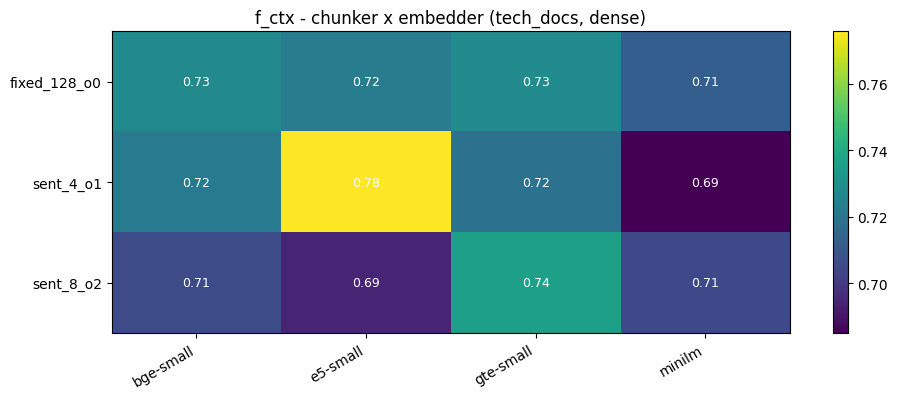

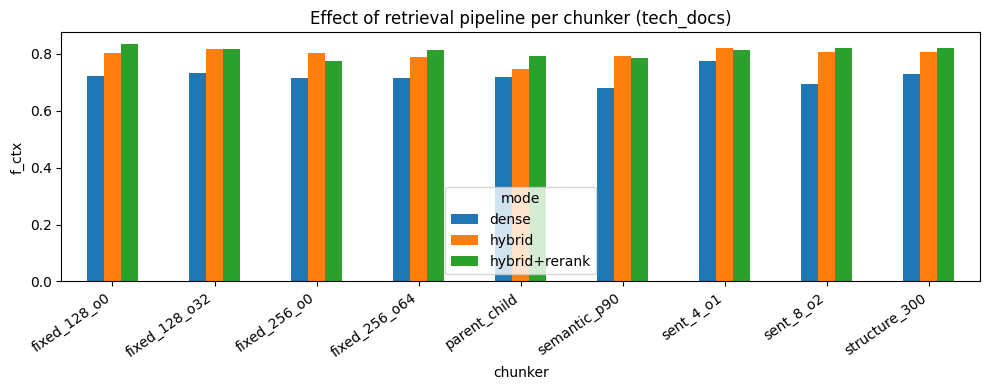

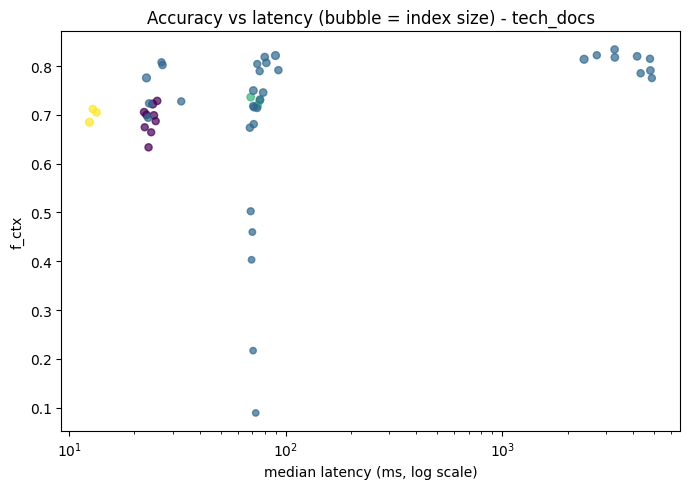

In [19]:
import matplotlib.pyplot as plt

def plot_heatmap(corpus):
    d = stage_df("2"); d = d[(d.corpus == corpus) & (d["mode"] == "dense")]
    if d.empty: return
    pv = d.pivot_table(index="chunker", columns="embedder", values="f_ctx")
    fig, ax = plt.subplots(figsize=(1.7 * len(pv.columns) + 3, 0.7 * len(pv) + 2))
    im = ax.imshow(pv.values, aspect="auto"); ax.set_xticks(range(len(pv.columns))); ax.set_xticklabels(pv.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(pv.index))); ax.set_yticklabels(pv.index)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            ax.text(j, i, f"{pv.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=9)
    ax.set_title(f"f_ctx - chunker x embedder ({corpus}, dense)"); fig.colorbar(im); plt.tight_layout()
    fig.savefig(OUT_DIR / f"heatmap_{corpus}.png", dpi=160); plt.show()

def plot_pipeline_effect(corpus):
    d = stage_df("3a"); d = d[d.corpus == corpus]
    if d.empty: return
    pv = d.pivot_table(index="chunker", columns="mode", values="f_ctx")[MODES]
    fig, ax = plt.subplots(figsize=(10, 4)); pv.plot(kind="bar", ax=ax)
    ax.set_ylabel("f_ctx"); ax.set_title(f"Effect of retrieval pipeline per chunker ({corpus})"); plt.xticks(rotation=35, ha="right"); plt.tight_layout()
    fig.savefig(OUT_DIR / f"pipeline_{corpus}.png", dpi=160); plt.show()

def plot_pareto(corpus):
    d = results_df(); d = d[(d.corpus == corpus) & (d.stage != "3b")].drop_duplicates("key")
    if d.empty: return
    fig, ax = plt.subplots(figsize=(7, 5))
    sc = ax.scatter(d.lat_p50_ms, d.f_ctx, s=20 + 8 * np.sqrt(d.index_mb.clip(lower=0.01)), c=pd.factorize(d.embedder)[0], alpha=0.7)
    ax.set_xscale("log"); ax.set_xlabel("median latency (ms, log scale)"); ax.set_ylabel("f_ctx")
    ax.set_title(f"Accuracy vs latency (bubble = index size) - {corpus}"); plt.tight_layout()
    fig.savefig(OUT_DIR / f"pareto_{corpus}.png", dpi=160); plt.show()

for corpus in GOLD:
    plot_heatmap(corpus); plot_pipeline_effect(corpus); plot_pareto(corpus)

## 17. Decision matrix (the main deliverable)
For each corpus and priority (accuracy / speed / low storage cost / balanced) we score every evaluated configuration by a weighted mix of normalised **f_ctx**, **latency** and **index size**, and report the winner. The same logic powers the advisor app below.

In [20]:
WEIGHTS = {"accuracy": (0.8, 0.1, 0.1), "speed": (0.4, 0.5, 0.1), "low_cost": (0.4, 0.1, 0.5), "balanced": (0.5, 0.25, 0.25)}

def _norm(s, invert=False):
    s = s.astype(float); rng = s.max() - s.min()
    z = (s - s.min()) / rng if rng > 0 else pd.Series(1.0, index=s.index)
    return 1 - z if invert else z

def score_table(df, corpus, w):
    d = df[(df.corpus == corpus) & (df.stage != "3b")].drop_duplicates("key").dropna(subset=["f_ctx"]).copy()
    if d.empty: return d
    d["score"] = w[0] * _norm(d.f_ctx) + w[1] * _norm(np.log1p(d.lat_p50_ms), invert=True) + w[2] * _norm(np.log1p(d.index_mb), invert=True)
    return d.sort_values("score", ascending=False)

def build_decision_matrix():
    df = results_df(); rows = []
    for corpus in sorted(df.corpus.unique()):
        for prio, w in WEIGHTS.items():
            t = score_table(df, corpus, w)
            if t.empty: continue
            b = t.iloc[0]
            rows.append(dict(corpus=corpus, priority=prio, chunker=b.chunker, embedder=b.embedder, mode=b["mode"], dim=b.dim, quant=b.quant or "-",
                             f_ctx=round(b.f_ctx, 3), recall=round(b.recall, 3), precision=round(b.precision, 3),
                             lat_p50_ms=round(b.lat_p50_ms, 1), index_mb=round(b.index_mb, 2)))
    return pd.DataFrame(rows)

DECISION = build_decision_matrix()
DECISION.to_csv(OUT_DIR / "decision_matrix.csv", index=False)
display(DECISION)

,corpus,priority,chunker,embedder,mode,dim,quant,f_ctx,recall,precision,lat_p50_ms,index_mb
0,tech_docs,accuracy,structure_300,e5-small,hybrid,384,-,0.808,0.913,0.778,26.7,0.52
1,tech_docs,speed,structure_300,e5-small,hybrid,384,-,0.808,0.913,0.778,26.7,0.52
2,tech_docs,low_cost,fixed_256_o0,e5-small,hybrid,384,-,0.804,0.886,0.792,73.8,0.43
3,tech_docs,balanced,structure_300,e5-small,hybrid,384,-,0.808,0.913,0.778,26.7,0.52


## 18. Cross-provider robustness check (optional but a strong result)
Run Stage 3b once with `PROVIDER=gemini`, then change `PROVIDER` (cell 1 or `.env`) to `openrouter`, re-run Stage 3b, and compare. If the *ranking* of configurations stays the same, your conclusions do not depend on one particular generator / judge.

In [21]:
from scipy.stats import spearmanr

def provider_agreement(prov_a="gemini", prov_b="openrouter", metrics=("groundedness", "correctness")):
    df = results_df(); df = df[df.stage == "3b"]
    a = df[df.provider == prov_a].set_index("key"); b = df[df.provider == prov_b].set_index("key")
    common = a.index.intersection(b.index)
    if len(common) < 3:
        print(f"Need >=3 shared configurations scored by both providers (found {len(common)}). Run Stage 3b with each provider."); return
    for m in metrics:
        rho, p = spearmanr(a.loc[common, m], b.loc[common, m])
        print(f"{m:13s} Spearman rho = {rho:.2f} (p={p:.3f}) over {len(common)} configs | mean {prov_a}={a.loc[common, m].mean():.3f}  mean {prov_b}={b.loc[common, m].mean():.3f}")

provider_agreement("gemini", "openrouter")

Need >=3 shared configurations scored by both providers (found 0). Run Stage 3b with each provider.


## 19. Config Advisor app (Streamlit)
Writes `advisor_app.py`. Run it from a terminal in this folder: `streamlit run advisor_app.py`. Users choose a document type and slide priorities (accuracy / speed / storage) and get the best-scoring configuration from *your* experiments.

In [22]:
%%writefile advisor_app.py
import numpy as np, pandas as pd, streamlit as st

st.set_page_config(page_title="RAG Config Advisor", layout="wide")
st.title("RAG Config Advisor")
st.caption("Recommendations come from our chunking x embedding x retrieval experiments (outputs/results.csv).")

df = pd.read_csv("outputs/results.csv")
df = df[(df.stage != "3b")].drop_duplicates("key").dropna(subset=["f_ctx"])

corpus = st.sidebar.selectbox("Document type", sorted(df.corpus.unique()))
st.sidebar.markdown("**Priorities**")
w_acc = st.sidebar.slider("Retrieval accuracy", 0.0, 1.0, 0.6)
w_lat = st.sidebar.slider("Low latency", 0.0, 1.0, 0.2)
w_sz = st.sidebar.slider("Small index / low cost", 0.0, 1.0, 0.2)
modes = st.sidebar.multiselect("Allowed retrieval modes", sorted(df["mode"].unique()), default=sorted(df["mode"].unique()))
embs = st.sidebar.multiselect("Allowed embedders", sorted(df.embedder.unique()), default=sorted(df.embedder.unique()))

d = df[(df.corpus == corpus) & df["mode"].isin(modes) & df.embedder.isin(embs)].copy()
def norm(s, inv=False):
    s = s.astype(float); r = s.max() - s.min()
    z = (s - s.min()) / r if r > 0 else pd.Series(1.0, index=s.index)
    return 1 - z if inv else z
tot = max(w_acc + w_lat + w_sz, 1e-9)
d["score"] = (w_acc * norm(d.f_ctx) + w_lat * norm(np.log1p(d.lat_p50_ms), True) + w_sz * norm(np.log1p(d.index_mb), True)) / tot
d = d.sort_values("score", ascending=False)

if d.empty:
    st.warning("No configuration matches these filters.")
else:
    best = d.iloc[0]
    st.subheader("Recommended setup")
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Chunking", best.chunker); c2.metric("Embedding", best.embedder)
    c3.metric("Retrieval", best["mode"]); c4.metric("Vector size", f"{int(best.dim)}-d {best.quant if isinstance(best.quant, str) and best.quant else ''}")
    m1, m2, m3, m4 = st.columns(4)
    m1.metric("f_ctx", f"{best.f_ctx:.3f}"); m2.metric("Recall", f"{best.recall:.3f}")
    m3.metric("Median latency (ms)", f"{best.lat_p50_ms:.1f}"); m4.metric("Index size (MB)", f"{best.index_mb:.2f}")
    st.subheader("Top 10 alternatives")
    st.dataframe(d[["chunker", "embedder", "mode", "dim", "quant", "f_ctx", "recall", "precision", "lat_p50_ms", "index_mb", "score"]].head(10).round(3), use_container_width=True)

Writing advisor_app.py


## 20. Wrap-up checklist (for the IEEE report and demo)
**Artifacts produced** (all in `outputs/`): `results.csv`, `decision_matrix.csv`, `heatmap_*.png`, `pipeline_*.png`, `pareto_*.png`, plus `advisor_app.py`.

**Report structure (10 pages, IEEE):** Introduction & gap → Related work → Method (corpora, chunkers, embedders, retrieval modes, metrics definitions) → Gold-set construction & verification → Results per stage with CIs → H1/H2/H3 findings → Decision matrix & advisor → Limitations → Conclusion.

**Be explicit about limitations:** gold questions are LLM-drafted (hand-verified), a question may be answerable from other passages (this affects every config equally), generation/judge quality depends on the chosen provider, `semantic_p90` uses `SEM_EMBED_NAME` only for splitting, and binary quantization here is plain sign-bit without calibration.

**Log for reproducibility:** library versions, provider + model name + date for every LLM run (stored in `results.csv`), random seed (`SEED`), and the verified gold CSVs.

**If something looks wrong:** set `FAST_MODE = True` for a tiny end-to-end check, or `hashing-bow` as the embedder to test the pipeline without downloading any model.